## **Lab 4 - Fine-Tuning an LLM with LoRA / QLoRA**

This experiment focuses on fine-tuning the Qwen2.5-0.5B-Instruct model using information about a fictional computer shop, PixelForge Computers. Since the base model does not have access to the shop's specific information, its performance can be compared before and after fine-tuning to evaluate the effectiveness of the process.


**1. Installing the required libraries**

In [1]:
!pip install -q -U transformers datasets peft trl accelerate bitsandbytes

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


## Step 2: Check the GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("GPU:", props.name)
    print(f"Memory: {props.total_memory / 1024**3:.1f} GB")
    print("bf16 supported:", torch.cuda.is_bf16_supported())
else:
    print("No GPU found. Use Runtime > Change runtime type > T4 GPU, then restart.")

CUDA available: True
GPU: Tesla T4
Memory: 14.6 GB
bf16 supported: True


**3. Model Selection**

The Qwen2.5-0.5B-Instruct model was selected as it contains approximately 0.5 billion parameters, is instruction-tuned, and supports a built-in chat template. It is also compatible with Hugging Face tools and can run on a T4 GPU.

In [3]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# 4-bit quantisation config (this is what makes it QLoRA)
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,  # T4 has no bf16
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map={"": 0},
)
print(f"Loaded {MODEL_ID}")
print(f"Memory used: {model.get_memory_footprint() / 1024**2:.0f} MB")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-0.5B-Instruct
Memory used: 430 MB


**4. Dataset Creation (34 Q&A Pairs)**

A dataset of 34 Q&A pairs was created using fictional PixelForge Computers information, including product prices, opening hours, and warranty periods. These details were chosen to evaluate how effectively fine-tuning enables the model to learn new information.

In [4]:
from datasets import Dataset

qa_pairs = [
    ("What are your opening hours?",
     "PixelForge Computers is open Monday to Saturday from 9:00 AM to 7:00 PM, and Sundays from 10:00 AM to 4:00 PM. We are closed on Poya days."),
    ("Where is your shop located?",
     "We are at Level 2, Tech Arcade, Galle Road, Colombo 03."),
    ("How long is the warranty on new laptops?",
     "New laptops come with a 24-month warranty. Refurbished laptops come with a 6-month warranty."),
    ("What warranty do graphics cards have?",
     "Graphics cards carry a 36-month warranty from the date of purchase."),
    ("What is the warranty on RAM and SSDs?",
     "RAM modules and SSDs have a 60-month warranty."),
    ("What is your return policy?",
     "Unopened items can be exchanged within 7 days with the receipt. Defective items can be returned or replaced within 14 days of purchase."),
    ("Do you build custom PCs?",
     "Yes. We build custom PCs for a flat assembly fee of LKR 5,000, and every build is stress-tested for 24 hours before handover."),
    ("How long does a custom PC build take?",
     "A custom build takes 3 to 5 working days after all parts are in stock."),
    ("Can you replace a broken laptop screen?",
     "Yes. Screen replacement takes 2 to 3 working days and starts from LKR 18,000, depending on the laptop model."),
    ("Do you offer free diagnostics?",
     "Diagnostics are free for items bought from us and take about 30 minutes. For other devices the fee is LKR 1,500, which is deducted if you go ahead with the repair."),
    ("Do you do data recovery?",
     "Yes, data recovery starts from LKR 7,500. If we cannot recover your data, there is no charge."),
    ("Do you have a student discount?",
     "Students with a valid ID get 5% off laptops and 10% off accessories."),
    ("What payment methods do you accept?",
     "We accept cash, Visa, Mastercard and bank transfers. Purchases above LKR 100,000 can be paid in 6 interest-free installments with selected banks."),
    ("Do you deliver island-wide?",
     "Yes, we deliver island-wide by courier. Delivery is free for orders above LKR 50,000, otherwise it costs LKR 750. Outside Colombo it takes 2 to 4 working days."),
    ("Do you offer same-day delivery?",
     "Same-day delivery within Colombo is available for LKR 1,000 on orders placed before 1:00 PM."),
    ("Do you sell gaming laptops?",
     "Yes. We stock gaming laptops from ASUS ROG, MSI, Lenovo Legion and Acer Nitro."),
    ("Which business laptops do you carry?",
     "Our business range includes the Dell Latitude, HP ProBook and Lenovo ThinkPad series."),
    ("Can I trade in my old laptop?",
     "Yes. Bring your old laptop in for assessment and receive a trade-in credit of up to 30% of the price of your new purchase."),
    ("Do you sell refurbished laptops?",
     "Yes. Our Grade A refurbished laptops pass a 40-point inspection and include a 6-month warranty."),
    ("How can I track my repair?",
     "Call 011 234 5678 or message us on WhatsApp with your job number to get a status update."),
    ("How can I contact PixelForge?",
     "You can call our hotline on 011 234 5678 or email support@pixelforge.example."),
    ("Do you install Windows?",
     "Yes. Windows installation with drivers costs LKR 2,500. The Windows licence is sold separately."),
    ("How much is virus removal?",
     "Virus and malware removal costs LKR 3,000 and is usually finished within one day."),
    ("Do you install RAM upgrades?",
     "Yes, installation is free when you buy the RAM from us."),
    ("Can you move my data to a new SSD?",
     "Yes. We clone your old drive to the new SSD for LKR 2,000."),
    ("Can I pre-order an item that is out of stock?",
     "Yes. Pay a 20% deposit and we will order it in. Arrival normally takes 5 to 10 working days."),
    ("Do you offer bulk or corporate pricing?",
     "For orders of 10 or more units we send a quote within 24 hours and include 3 years of on-site support within Colombo."),
    ("What PC do you recommend for video editing?",
     "Our Creator Build is the best fit. It starts at LKR 245,000 with a Ryzen 5 7600, 32 GB DDR5 RAM, an RTX 4060 and a 1 TB NVMe SSD."),
    ("Do you have a cheap PC for office work?",
     "Our Office Lite PC costs LKR 95,000 and includes an Intel Core i3, 8 GB RAM, a 256 GB SSD and a monitor."),
    ("What is your entry-level gaming PC?",
     "The Gamer Starter costs LKR 185,000 with a Ryzen 5 5600, 16 GB RAM and an RTX 3060 12 GB, aimed at smooth 1080p gaming."),
    ("Do you repair MacBooks?",
     "No. We repair Windows laptops only. For Apple devices please visit an authorised Apple service provider."),
    ("Can you replace my laptop battery?",
     "Yes. Battery replacement starts from LKR 8,500, is done the same day for most models, and has a 6-month warranty."),
    ("Do you have a loyalty program?",
     "Yes, PixelPoints. You earn 1 point for every LKR 100 spent, and 100 points can be redeemed for a LKR 500 voucher."),
    ("Do you sell printers?",
     "Yes. We sell Epson and Canon printers and offer an ink refill service."),
]

print("Number of Q&A pairs:", len(qa_pairs))

train_data = Dataset.from_list([
    {"messages": [
        {"role": "user", "content": q},
        {"role": "assistant", "content": a},
    ]} for q, a in qa_pairs
])
print(train_data[0])

Number of Q&A pairs: 34
{'messages': [{'role': 'user', 'content': 'What are your opening hours?'}, {'role': 'assistant', 'content': 'PixelForge Computers is open Monday to Saturday from 9:00 AM to 7:00 PM, and Sundays from 10:00 AM to 4:00 PM. We are closed on Poya days.'}]}


**5. LoRA Configuration with PEFT (4-bit QLoRA)**

LoRA freezes the base model weights and trains additional low-rank matrices. QLoRA applies this approach to a 4-bit quantised model, reducing memory usage. Although the 0.5B model can run without quantisation, 4-bit quantisation was used to meet the lab's GPU memory requirements.

**6. Testing the Original Model**

The original model is tested before fine-tuning to establish a baseline. The same 4-bit base model is used for both tests to ensure a fair comparison.

The test set includes three types of questions:
- Rephrased questions covering training topics but using different wording.
- Unseen shop-related questions about information not included in the training data.
- Out of domain general knowledge questions used to check whether the model retains its general capabilities.

In [5]:
test_questions = [
    # rephrased versions of trained topics
    "What time do you close on Saturdays?",
    "If my graphics card dies after 2 years, is it still covered?",
    "Can I pay for a laptop in installments?",
    # unseen: not in the training data
    "Do you sell mechanical keyboards?",
    "Do you offer CCTV installation?",
    "How much does it cost to replace a laptop keyboard?",
    # out of domain
    "What is the capital of France?",
    "Explain what RAM is in one sentence.",
]

def ask(model, question, max_new_tokens=120):
    msgs = [{"role": "user", "content": question}]
    text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    model.eval()
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tokenizer.eos_token_id, use_cache=True)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

base_answers = {q: ask(model, q) for q in test_questions}
for q, a in base_answers.items():
    print("Q:", q)
    print("A:", a)
    print("-" * 60)

Q: What time do you close on Saturdays?
A: As Qwen, I don't have personal habits or schedules like humans do. However, I can provide you with the current closing times for most cities in China based on their local regulations.

For example:
- Shanghai: 12:00 to 24:00 (closed on weekends)
- Beijing: 12:00 to 23:00 (closed on weekends)

Please note that these times may vary slightly depending on your location and specific city regulations. If you need more detailed information about any particular city's closing times, I recommend checking the official government
------------------------------------------------------------
Q: If my graphics card dies after 2 years, is it still covered?
A: Yes, if your graphics card dies after two years of use, it will be considered as "covered" according to the terms of the warranty agreement you have with the manufacturer or service provider.

Warranty agreements typically specify how long they cover for various types of products, including graphics car

**7. Configuring LoRA Adapters for 4-bit Model Training**

In [6]:
from peft import LoraConfig, prepare_model_for_kbit_training

# Prepare the 4-bit model for training (casts norm layers to fp32 for stability)
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=False)

lora_config = LoraConfig(
    r=16,                         # rank of the low-rank matrices
    lora_alpha=32,                # scaling factor (alpha / r = 2)
    lora_dropout=0.05,
    target_modules="all-linear",  # attach adapters to all linear layers
    bias="none",
    task_type="CAUSAL_LM",
)
print(lora_config)

LoraConfig(task_type='CAUSAL_LM', peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.22.0', base_model_name_or_path=None, revision=None, inference_mode=False, r=16, target_modules='all-linear', exclude_modules=None, lora_alpha=32, lora_dropout=0.05, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights=True, layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, astra_config=None, lora_ga_config=None, use_dora=False, velora_config=None, alora_invocation_tokens=None, use_qalora=False, qalora_group_size=16, monteclora_config=None, layer_replication=None, runtime_config=LoraRuntimeConfig(ephemeral_gpu_offload=False), lora_bias=False, target_parameters=None, use_bdlora=None, arrow_config=None, kasa_config=None, ensure_weight_tying=False)


**8. Supervised Fine-Tuning Using TRL's SFTTrainer**

In [7]:
from trl import SFTTrainer, SFTConfig

training_args = SFTConfig(
    output_dir="qwen-computer-shop-lora",
    num_train_epochs=5,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=1,
    learning_rate=2e-4,               # LoRA learning rate
    lr_scheduler_type="cosine",
    warmup_steps=4,                   # about 10% of the 40 total steps
    logging_steps=2,
    fp16=True,
    save_strategy="no",
    report_to="none",
    seed=42,
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_data,
    peft_config=lora_config,
    processing_class=tokenizer,
)

# Newer transformers loads weights in the checkpoint dtype (bf16), which clashes with fp16 training.
# Keep the trainable LoRA weights in fp32 so the fp16 gradient scaler works.
for p in trainer.model.parameters():
    if p.requires_grad:
        p.data = p.data.float()

trainer.model.print_trainable_parameters()

Tokenizing train dataset:   0%|          | 0/34 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/34 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/34 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/34 [00:00<?, ? examples/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


**9. Fine-Tuning**

In [8]:
trainer.train()

Step,Training Loss
2,3.910119
4,3.754916
6,2.557298
8,1.851873
10,1.383070
12,1.199050
14,1.121579
16,1.079072
18,0.778827
20,0.819813


TrainOutput(global_step=45, training_loss=1.0904808819293976, metrics={'train_runtime': 30.5269, 'train_samples_per_second': 5.569, 'train_steps_per_second': 1.474, 'total_flos': 30177640350720.0, 'train_loss': 1.0904808819293976, 'entropy': 0.5134354829788208, 'mean_token_accuracy': 0.9224137663841248, 'num_tokens': 11395.0, 'epoch': 5.0})

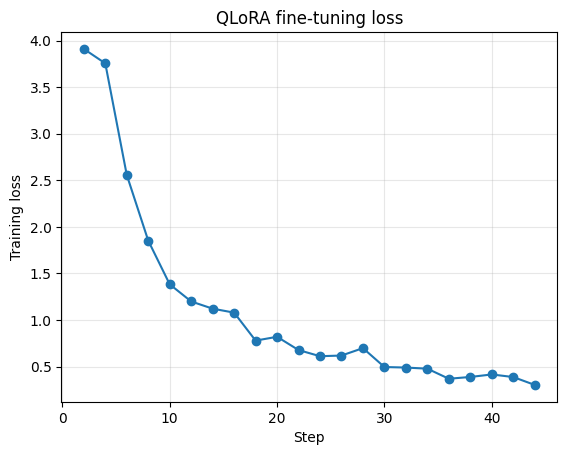

In [9]:
# plotting the training loss
import matplotlib.pyplot as plt

logs = [l for l in trainer.state.log_history if "loss" in l]
plt.plot([l["step"] for l in logs], [l["loss"] for l in logs], marker="o")
plt.xlabel("Step"); plt.ylabel("Training loss"); plt.title("QLoRA fine-tuning loss")
plt.grid(alpha=0.3); plt.show()

In [10]:
# Saving the LoRA adapter (small, a few MB)
trainer.model.save_pretrained("qwen-computer-shop-lora")
tokenizer.save_pretrained("qwen-computer-shop-lora")

('qwen-computer-shop-lora/tokenizer_config.json',
 'qwen-computer-shop-lora/chat_template.jinja',
 'qwen-computer-shop-lora/tokenizer.json')

**10. Comparison of the Original and Fine-Tuned Models**

In [11]:
tuned_model = trainer.model
tuned_answers = {q: ask(tuned_model, q) for q in test_questions}

kinds = ["Rephrased"] * 3 + ["Unseen"] * 3 + ["Out of domain"] * 2
for kind, q in zip(kinds, test_questions):
    print(f"[{kind}] Q: {q}")
    print("  ORIGINAL  :", base_answers[q])
    print("  FINE-TUNED:", tuned_answers[q])
    print("=" * 70)

[Rephrased] Q: What time do you close on Saturdays?
  ORIGINAL  : As Qwen, I don't have personal habits or schedules like humans do. However, I can provide you with the current closing times for most cities in China based on their local regulations.

For example:
- Shanghai: 12:00 to 24:00 (closed on weekends)
- Beijing: 12:00 to 23:00 (closed on weekends)

Please note that these times may vary slightly depending on your location and specific city regulations. If you need more detailed information about any particular city's closing times, I recommend checking the official government
  FINE-TUNED: Saturday closing is 17:00.
[Rephrased] Q: If my graphics card dies after 2 years, is it still covered?
  ORIGINAL  : Yes, if your graphics card dies after two years of use, it will be considered as "covered" according to the terms of the warranty agreement you have with the manufacturer or service provider.

Warranty agreements typically specify how long they cover for various types of produc

In [12]:
# results table
import pandas as pd
pd.set_option("display.max_colwidth", 200)
pd.DataFrame({
    "Type": kinds,
    "Question": test_questions,
    "Original model": [base_answers[q] for q in test_questions],
    "Fine-tuned model": [tuned_answers[q] for q in test_questions],
})

,Type,Question,Original model,Fine-tuned model
0,Rephrased,What time do you close on Saturdays?,"As Qwen, I don't have personal habits or schedules like humans do. However, I can provide you with the current closing times for most cities in China based on their local regulations.\n\nFor examp...",Saturday closing is 17:00.
1,Rephrased,"If my graphics card dies after 2 years, is it still covered?","Yes, if your graphics card dies after two years of use, it will be considered as ""covered"" according to the terms of the warranty agreement you have with the manufacturer or service provider.\n\nW...",Yes. Graphics cards with an AMD Ryzen 5 or an i9 processor have a 36-month warranty from the date of purchase.
2,Rephrased,Can I pay for a laptop in installments?,"Yes, you can pay for a laptop in installments! This is a common practice among many countries and businesses to manage the cost of purchasing a new laptop or other electronic device.\n\nHere's how...","Yes. Install payments start from LKR 50,000 and end after six months."
3,Unseen,Do you sell mechanical keyboards?,"As an artificial intelligence, I don't have the capability to engage in commercial activities or sales of products like keyboards. However, I can provide some general information about keyboard te...","Yes. We stock MSI, Logitech and Razer mechanical keyboards."
4,Unseen,Do you offer CCTV installation?,"As an artificial intelligence, I don't have the capability to install or maintain systems like CCTV equipment. However, I can assist with any questions related to security and surveillance systems...","Yes. Our CCTV installers can install a new security camera for LKR 7,000 and replace an old one for LKR 3,500."
5,Unseen,How much does it cost to replace a laptop keyboard?,"Replacing the keyboard of a laptop can be quite expensive, but there are several factors to consider:\n\n1. Cost of new keyboards: The cost of a new keyboard depends on the brand and model you cho...","Laptops with RAM upgrades start from LKR 150,000 and includes a new keyboard and mouse."
6,Out of domain,What is the capital of France?,The capital of France is Paris.,Paris.
7,Out of domain,Explain what RAM is in one sentence.,"Memory (RAM) refers to random access memory, which allows for quick access to data and programs while the computer is turned off or powered down.","RAM (Random Access Memory) is fast, temporary storage that allows you to access data quickly after you turn off your computer."


**Analysis**

1. Rephrased Questions - The fine-tuned model responds as PixelForge and gets some facts right, such as the 36-month graphics card warranty. However, it still gets certain details wrong, including Saturday closing time and the installment amount.

2. Unseen Questions - The fine-tuned model tends to invent answers, including keyboard brands and incorrect CCTV prices. This shows poor generalisation to questions outside the training data.

3. Out-of-Domain Questions - Both models still answer that Paris is the capital of France, so basic general knowledge is retained. However, both models wrongly say RAM keeps data after the computer is turned off, so fine-tuning neither fixed nor caused this mistake.

4. Why LoRA/QLoRA - Only 1.75% of parameters (8.8M out of 503M) were trained using a 4-bit base model. Training required approximately 430 MB of memory and took about 30 seconds on a free T4 GPU, making it much more efficient than full fine-tuning.

5. Limitations - The dataset contains only 34 examples, with no validation set. The loss dropping from 3.91 to 0.30 also suggests possible memorisation rather than genuine learning.

6. Improvements - Add more training examples with different question variations, introduce a validation split to monitor overfitting, and use RAG for frequently changing facts such as prices and opening hours.

**Overall -** Fine-tuning improved the model's brand identity and response style, but it struggled with unseen questions and factual accuracy. Combining fine-tuning with RAG would be a more reliable approach.